**Student name(s):** [YOUR NAME] *(replace with your name — add a second/third name+ID here if working in a group)*
**Student ID(s):** [YOUR STUDENT ID]
**Course:** Exploratory Data Analysis
**Assignment:** EDA — Assignment 3: Bivariate EDA
**Dataset name:** NBA All Elo (NBA & ABA game results and Elo ratings, 1947–2009) — same dataset as Assignments 1 and 2
**Dataset source:** FiveThirtyEight, public data repository — https://github.com/fivethirtyeight/data/tree/master/nba-elo

> **Before submitting:** fill in your real name(s)/ID(s) above, then rename this file appropriately (e.g. `A3_LastName1_LastName2_EDA.ipynb`).

# EDA Assignment 3 — Bivariate EDA

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
%matplotlib inline

In [2]:
# Same dataset and loading logic as Assignments 1 and 2: use the local cache if
# it exists, otherwise download from the original public source.
DATA_URL = "https://raw.githubusercontent.com/fivethirtyeight/data/master/nba-elo/nbaallelo.csv"
CACHE_PATH = "data/nbaallelo.csv"

if os.path.exists(CACHE_PATH):
    df = pd.read_csv(CACHE_PATH)
else:
    df = pd.read_csv(DATA_URL)
    os.makedirs("data", exist_ok=True)
    df.to_csv(CACHE_PATH, index=False)

df.shape

(110902, 23)

### Unit of analysis: one row per game

Every game appears **twice** in the raw file — once from each team's point of view (`_iscopy` = 0 / 1), with `pts` and `opp_pts` swapped and the margin mirrored. For bivariate work this matters: keeping both copies would count each game twice and add a mirrored point `(-x, -y)` for every point `(x, y)`, which artificially strengthens correlations involving signed variables like the margin. I therefore keep only the `_iscopy == 0` row of each game, which (as checked below) is always the **home team's** row (or the nominal home team at a neutral site). All signed variables are therefore read *from the home team's perspective*.

Derived variables used throughout:
- `elo_diff = elo_i - opp_elo_i` — home team's pre-game Elo advantage (positive = home team rated higher).
- `margin = pts - opp_pts` — home team's final margin (positive = home win). `abs_margin` is the same as in A2.
- `era` — the season grouped into five scoring eras (based on A1/A2 scoring trends and major rule changes: the 24-second shot clock arrived in 1954–55, the ABA merger in 1976, the three-point line in 1979–80).
- `season_type` — regular season vs playoffs.

In [3]:
games = df[df["_iscopy"] == 0].copy()
print("Rows in raw file:", len(df), "| games (one row each):", len(games))
print("game_location of the kept rows:", games["game_location"].value_counts().to_dict())

games["elo_diff"] = games["elo_i"] - games["opp_elo_i"]
games["margin"] = games["pts"] - games["opp_pts"]
games["abs_margin"] = games["margin"].abs()
games["home_win"] = (games["margin"] > 0).astype(int)

ERA_BINS = [1946, 1954, 1969, 1979, 1994, 2009]
ERA_LABELS = ["1947-54", "1955-69", "1970-79", "1980-94", "1995-2009"]
games["era"] = pd.cut(games["year_id"], bins=ERA_BINS, labels=ERA_LABELS)
games["season_type"] = np.where(games["is_playoffs"] == 1, "Playoffs", "Regular season")

games[["date_game", "team_id", "opp_id", "pts", "opp_pts", "elo_diff", "margin", "era", "season_type"]].head()

Rows in raw file: 110902 | games (one row each): 55451
game_location of the kept rows: {'H': 55438, 'N': 13}


,date_game,team_id,opp_id,pts,opp_pts,elo_diff,margin,era,season_type
0,11/1/1946,TRH,NYK,66,68,0.0000,-2,1947-54,Regular season
2,11/2/1946,CHS,NYK,63,47,-6.7233,16,1947-54,Regular season
4,11/2/1946,DTF,WSC,33,50,0.0000,-17,1947-54,Regular season
7,11/2/1946,PRO,BOS,59,53,0.0000,6,1947-54,Regular season
9,11/2/1946,STB,PIT,56,51,0.0000,5,1947-54,Regular season


In [4]:
# pandas computes Spearman via scipy, which is not installed in this environment.
# Spearman's rho is by definition the Pearson correlation of the ranks, so we compute it directly.
def pearson(x, y):
    return x.corr(y)

def spearman(x, y):
    return x.rank().corr(y.rank())

def corr_pair(data, x, y):
    return pd.Series({"Pearson r": pearson(data[x], data[y]), "Spearman rho": spearman(data[x], data[y])})

## 1. Select Variable Pairs

| Pair | Variable 1 | Variable 2 | Why investigate? |
|---|---|---|---|
| 1 | `elo_diff` (home Elo − away Elo, numerical) | `margin` (home pts − away pts, numerical) | Directly follows the A2 question *"do bigger Elo gaps predict bigger blowouts, not just more likely wins?"* If Elo measures team strength, a bigger pre-game gap should translate into a bigger final margin. This tests how much of a game's outcome is predictable before tip-off. |
| 2 | `pts` (home points, numerical) | `opp_pts` (away points, numerical) | Do teams score more when their opponent scores more? A positive association would point to a shared *game environment* (pace, era, rules, overtime) rather than "offense vs defense". It is also the pair on which the A2 outliers (forfeit, 186–184 game, 18–19 game) are most visible. |
| 3 | `year_id` (season, numerical) | `pts` (points per game, numerical) | A1 found clear scoring changes over time. Here I test whether a single correlation coefficient can describe that trend, or whether it is non-linear (rise and fall), which would make Pearson misleading. |

Categorical variables used in Sections 6–7: `era` (scoring era, derived from `year_id`) and `season_type` (regular season vs playoffs).

## 2. Numerical vs Numerical

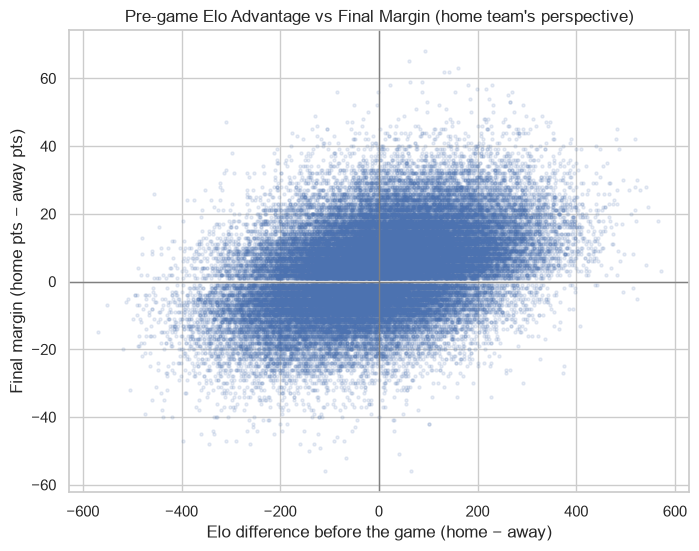

Least-squares line: margin = 3.88 + 0.0351 * elo_diff
-> +100 Elo points ≈ +3.5 points of margin; at equal Elo the home team wins by 3.9 on average
Std of margin: 12.8 points


In [5]:
# Scatterplot 1: Elo gap vs final margin
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(games["elo_diff"], games["margin"], s=5, alpha=0.12, color="#4C72B0", rasterized=True)
ax.axhline(0, color="gray", lw=1)
ax.axvline(0, color="gray", lw=1)
ax.set_title("Pre-game Elo Advantage vs Final Margin (home team's perspective)")
ax.set_xlabel("Elo difference before the game (home − away)")
ax.set_ylabel("Final margin (home pts − away pts)")
plt.show()

slope, intercept = np.polyfit(games["elo_diff"], games["margin"], 1)
print(f"Least-squares line: margin = {intercept:.2f} + {slope:.4f} * elo_diff")
print(f"-> +100 Elo points ≈ +{100 * slope:.1f} points of margin; at equal Elo the home team wins by {intercept:.1f} on average")
print(f"Std of margin: {games['margin'].std():.1f} points")

**Interpretation — `elo_diff` vs `margin`:**
- **Direction:** positive — the more highly rated the home team is relative to its opponent, the larger its winning margin tends to be.
- **Strength and shape:** moderate at best. The cloud is a wide, roughly elliptical band tilted upward with no visible curvature, so the relationship looks **linear**. The fitted line implies about **+3.5 points of margin per 100 Elo points**, but the vertical spread (std ≈ 12.8 points) is much larger than that, so any single game is hard to predict.
- **Clusters and unusual observations:** there are no separate clusters — one dense blob centred slightly *above* zero (the line crosses `elo_diff = 0` at ≈ +3.9 points, the home-court advantage seen in A1). Unusual points are the vertical extremes: e.g. the home team losing by 56 despite near-equal ratings, or the 148–80 Cleveland–Miami game from A2 (≈ 61 points above the fitted line).
- **Meaning:** Elo captures real differences in team strength — favourites do win by more — but the outcome of a single NBA game is still dominated by game-to-game variation. *"Bigger Elo gaps predict bigger margins, but only on average."*

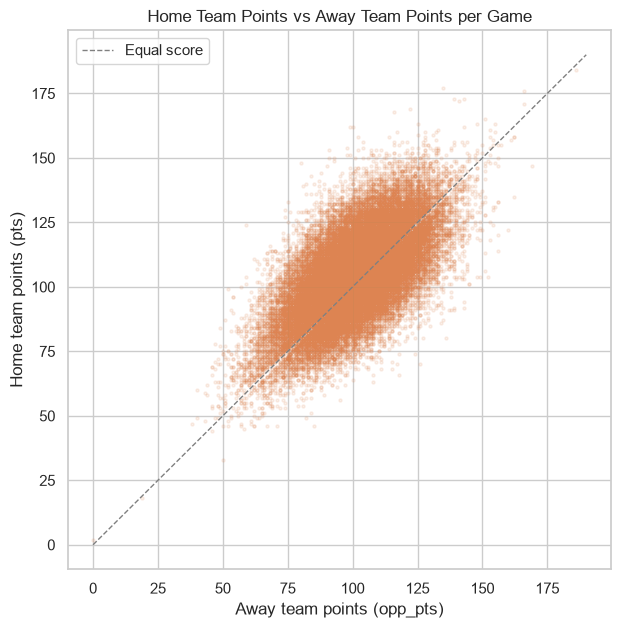

In [6]:
# Scatterplot 2: home points vs away points
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(games["opp_pts"], games["pts"], s=5, alpha=0.12, color="#DD8452", rasterized=True)
ax.plot([0, 190], [0, 190], color="gray", ls="--", lw=1, label="Equal score")
ax.set_title("Home Team Points vs Away Team Points per Game")
ax.set_xlabel("Away team points (opp_pts)")
ax.set_ylabel("Home team points (pts)")
ax.legend()
plt.show()

**Interpretation — `pts` vs `opp_pts`:**
- **Direction:** positive — high-scoring home performances go together with high-scoring away performances.
- **Strength and shape:** fairly strong for this kind of data; the cloud is an elongated ellipse along the diagonal and looks **linear**. Slightly more points lie above the dashed equal-score line than below it (home advantage).
- **Clusters and unusual observations:** a sparse "tail" of low-scoring games in the lower-left (scores in the 40s–70s) — these turn out to be mostly from the early, pre-shot-clock era (see Sections 5 and 7). Isolated extreme points include the forfeit (2–0, bottom-left corner) and the 186–184 triple-overtime game (top-right corner), both investigated in A2.
- **Meaning:** points scored and points allowed are *not* opposites in this data — both teams share the same game, the same rules, the same pace and the same number of minutes (including overtime). This positive association is therefore likely driven by the *game environment* rather than one team's scoring "causing" the other's (discussed further in Section 9).

## 3. Pearson and Spearman Correlation

In [7]:
corr_table = pd.DataFrame({
    "Pair 1: elo_diff vs margin": corr_pair(games, "elo_diff", "margin"),
    "Pair 2: pts vs opp_pts": corr_pair(games, "pts", "opp_pts"),
    "Pair 3: year_id vs pts": corr_pair(games, "year_id", "pts"),
}).T
corr_table["Pearson − Spearman"] = corr_table["Pearson r"] - corr_table["Spearman rho"]
corr_table.round(3)

,Pearson r,Spearman rho,Pearson − Spearman
Pair 1: elo_diff vs margin,0.409,0.406,0.003
Pair 2: pts vs opp_pts,0.636,0.610,0.027
Pair 3: year_id vs pts,-0.097,-0.213,0.116


**Comparison:**

- **Pair 1 (`elo_diff` vs `margin`): Pearson ≈ 0.41, Spearman ≈ 0.41.** Practically identical. This is what we expect when a relationship is linear and not driven by a few extreme points: ranking the data (Spearman) changes nothing, because the straight-line pattern holds throughout the range. A moderate positive association.
- **Pair 2 (`pts` vs `opp_pts`): Pearson ≈ 0.64, Spearman ≈ 0.61.** Both indicate a moderately strong positive association, with Pearson slightly *higher*. Pearson uses actual values, so games that are extreme on **both** axes (very low-scoring early games, very high-scoring overtime games, all lying along the diagonal) pull it up. Spearman only uses ranks, so those games count no more than any other — which is why it is a little lower. This is the reverse of the assignment example: here the extreme values *support* a linear pattern rather than hide a monotonic one.
- **Pair 3 (`year_id` vs `pts`): Pearson ≈ −0.10, Spearman ≈ −0.21.** Both are weak and they disagree by a factor of two — a warning sign. Scoring rose sharply in the 1950s, peaked in the 1960s and then declined, so the relationship is **neither linear nor monotonic**. Neither coefficient describes it well; Section 4 explores this.

Overall: when Pearson and Spearman agree (Pair 1), we can trust that a linear summary is reasonable; when they differ (Pairs 2 and 3), the difference points to extreme values or non-linearity that must be checked visually.

## 4. Nonlinear Relationships

**Pair chosen:** `year_id` vs `pts` (Pair 3). Because `statsmodels` (needed for seaborn's LOWESS) is not installed, the smoothing line is a **centred 5-season rolling average of the season means**, shown together with a straight least-squares line for comparison.

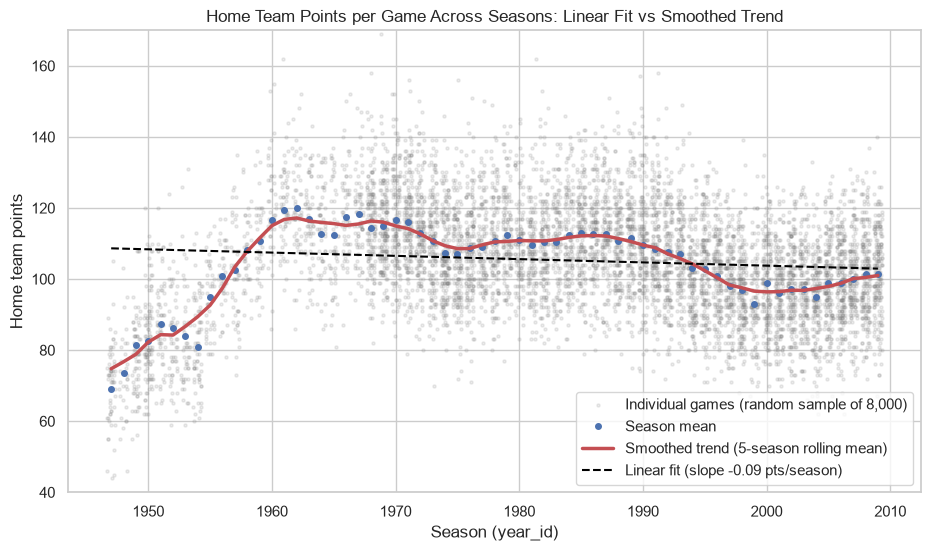

Share of variance in pts explained by a straight line in year_id:  0.009
Share of variance in pts explained by season means (any shape):     0.337
Peak season mean: 1962 (120.0 pts) | lowest: 1947 (69.2 pts)


In [8]:
season_means = games.groupby("year_id")["pts"].mean()
smooth = season_means.rolling(5, center=True, min_periods=1).mean()
b1, b0 = np.polyfit(games["year_id"], games["pts"], 1)

sample = games.sample(8000, random_state=1)
jitter = np.random.default_rng(1).uniform(-0.35, 0.35, len(sample))

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(sample["year_id"] + jitter, sample["pts"], s=5, alpha=0.15, color="gray",
           label="Individual games (random sample of 8,000)", rasterized=True)
ax.plot(season_means.index, season_means.values, "o", ms=4, color="#4C72B0", label="Season mean")
ax.plot(smooth.index, smooth.values, color="#C44E52", lw=2.5, label="Smoothed trend (5-season rolling mean)")
years = np.array([1947, 2009])
ax.plot(years, b0 + b1 * years, color="black", ls="--", lw=1.5, label=f"Linear fit (slope {b1:.2f} pts/season)")
ax.set_ylim(40, 170)
ax.set_title("Home Team Points per Game Across Seasons: Linear Fit vs Smoothed Trend")
ax.set_xlabel("Season (year_id)")
ax.set_ylabel("Home team points")
ax.legend(loc="lower right")
plt.show()

# How much of the variation in pts does each description explain?
r2_linear = pearson(games["year_id"], games["pts"]) ** 2
season_fitted = games["year_id"].map(season_means)
r2_season = 1 - ((games["pts"] - season_fitted) ** 2).sum() / ((games["pts"] - games["pts"].mean()) ** 2).sum()
print(f"Share of variance in pts explained by a straight line in year_id:  {r2_linear:.3f}")
print(f"Share of variance in pts explained by season means (any shape):     {r2_season:.3f}")
print("Peak season mean:", season_means.idxmax(), f"({season_means.max():.1f} pts)",
      "| lowest:", season_means.idxmin(), f"({season_means.min():.1f} pts)")

**Interpretation:** the relationship between season and scoring is clearly **non-linear**. Scoring rises steeply from about 69 points per game in 1947 to a peak of ~120 in the early 1960s (the 24-second shot clock arrived in 1954–55), stays on a high plateau of roughly 107–118 through the 1970s and 1980s, and then falls to the mid-90s around 1999–2004 before recovering slightly. The smoothed line follows this rise–plateau–decline, while the straight dashed line almost ignores it, sloping gently downward by about 0.09 points per season.

**Does Pearson describe it well? No.** Pearson r ≈ −0.10 suggests "almost no relationship", yet knowing the season explains about **34%** of the variation in points, compared with **under 1%** for a straight line in `year_id` (see the two variance shares printed above). A near-zero Pearson value here means *"no **straight-line** relationship"*, not *"no relationship"*. Spearman (−0.21) is not better: it only measures *monotonic* trends, and this trend changes direction.

## 5. Outliers and Relationships

**Pair chosen:** `pts` vs `opp_pts` (Pair 2), because this is where the A2 outliers live. Two kinds of unusual observations are examined:
1. **The specific games investigated in A2** that are extreme on this pair: the 1972 forfeit (Virginia 2 – Denver 0), and the 186–184 triple-overtime game (1983). I add a third one that shows up as extreme in this scatterplot: the 19–18 game of 22 November 1950 (Fort Wayne at Minneapolis), the lowest-scoring game in NBA history.
2. **All games where either team's score falls outside the A2 1.5×IQR fences** for `pts` (below 63 or above 143 points).

In [9]:
# A2 fences for pts (computed on the full team-game data, as in A2)
q1, q3 = df["pts"].quantile([0.25, 0.75])
lo_fence, hi_fence = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"A2 1.5xIQR fences for pts: [{lo_fence:.0f}, {hi_fence:.0f}]")

games["pts_outlier"] = (
    (games["pts"] < lo_fence) | (games["pts"] > hi_fence)
    | (games["opp_pts"] < lo_fence) | (games["opp_pts"] > hi_fence)
)
total = games["pts"] + games["opp_pts"]
named = games[(total <= 40) | (total >= 370)]
print("Games flagged by the A2 fences:", games["pts_outlier"].sum())
named[["date_game", "year_id", "team_id", "pts", "opp_id", "opp_pts", "notes"]]

A2 1.5xIQR fences for pts: [63, 143]
Games flagged by the A2 fences: 943


,date_game,year_id,team_id,pts,opp_id,opp_pts,notes
3190,11/22/1950,1951,MNL,18,FTW,19,NaN
26685,10/26/1972,1973,VIR,2,DNR,0,at Richmond VA; forfeit to VIR
50095,12/13/1983,1984,DEN,184,DET,186,NaN


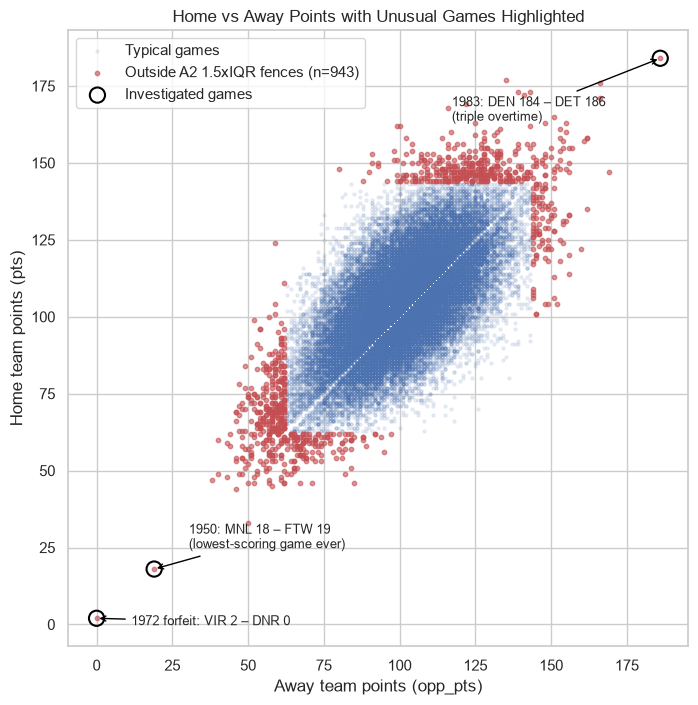

Flagged games by era:
era
1947-54      427
1955-69      136
1970-79      164
1980-94      160
1995-2009     56


In [10]:
# Unusual-observation visualization 1: scatterplot with flagged and named games highlighted
fig, ax = plt.subplots(figsize=(8, 8))
normal = games[~games["pts_outlier"]]
flagged = games[games["pts_outlier"]]
ax.scatter(normal["opp_pts"], normal["pts"], s=5, alpha=0.1, color="#4C72B0", label="Typical games", rasterized=True)
ax.scatter(flagged["opp_pts"], flagged["pts"], s=10, alpha=0.6, color="#C44E52",
           label=f"Outside A2 1.5xIQR fences (n={len(flagged)})")
ax.scatter(named["opp_pts"], named["pts"], s=120, facecolors="none", edgecolors="black", lw=1.5, label="Investigated games")
labels = {
    "forfeit": "1972 forfeit: VIR 2 – DNR 0",
    "low": "1950: MNL 18 – FTW 19\n(lowest-scoring game ever)",
    "high": "1983: DEN 184 – DET 186\n(triple overtime)",
}
for _, row in named.iterrows():
    key = "forfeit" if row["pts"] + row["opp_pts"] < 10 else ("low" if row["pts"] < 50 else "high")
    offset = {"forfeit": (25, -5), "low": (25, 15), "high": (-150, -45)}[key]
    ax.annotate(labels[key], (row["opp_pts"], row["pts"]), xytext=offset, textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))
ax.set_title("Home vs Away Points with Unusual Games Highlighted")
ax.set_xlabel("Away team points (opp_pts)")
ax.set_ylabel("Home team points (pts)")
ax.legend(loc="upper left")
plt.show()

print("Flagged games by era:")
print(flagged["era"].value_counts().sort_index().to_string())

**Investigating individual unusual observations:**

1. **1972 forfeit, Virginia 2 – Denver 0** (`notes`: *"at Richmond VA; forfeit to VIR"*). As established in A2, this is a correctly recorded *administrative* result, not a played game. On the scatterplot it sits alone in the bottom-left corner, far from every other game. It does not represent real scoring, but it is a genuine event in the record.
2. **22 Nov 1950, Minneapolis 18 – Fort Wayne 19.** A real, well-known game: Fort Wayne held the ball to stop George Mikan's Lakers from scoring, and this game is often cited as a key reason the NBA introduced the 24-second shot clock in 1954. It is an extreme but **genuine** observation, and it explains why so many low-scoring games belong to the 1947–54 era.
3. **13 Dec 1983, Denver 184 – Detroit 186** (from A2). A real record game played over three overtimes — both teams got 15 extra minutes, so *both* scores are inflated. This is a clear example of the "shared game environment" behind the positive correlation.

The colour-coded points also show that the 943 fence-flagged games are not random: about 45% of them (427) come from 1947–54, the low-scoring, pre-shot-clock era, and they sit mostly at the two ends of the main cloud (both teams low, or both teams high), not off to the sides.

In [11]:
scenarios = {
    "All games": games,
    "Without the 3 investigated games": games.drop(named.index),
    "Without the forfeit only": games[(games["pts"] + games["opp_pts"]) > 2],
    "Without all fence-flagged games": games[~games["pts_outlier"]],
}
outlier_effect = pd.DataFrame({k: corr_pair(v, "pts", "opp_pts") for k, v in scenarios.items()}).T
outlier_effect["n games"] = [len(v) for v in scenarios.values()]
outlier_effect.round(4)

,Pearson r,Spearman rho,n games
All games,0.6363,0.6097,55451
Without the 3 investigated games,0.6356,0.6096,55448
Without the forfeit only,0.6360,0.6097,55450
Without all fence-flagged games,0.6068,0.5937,54508


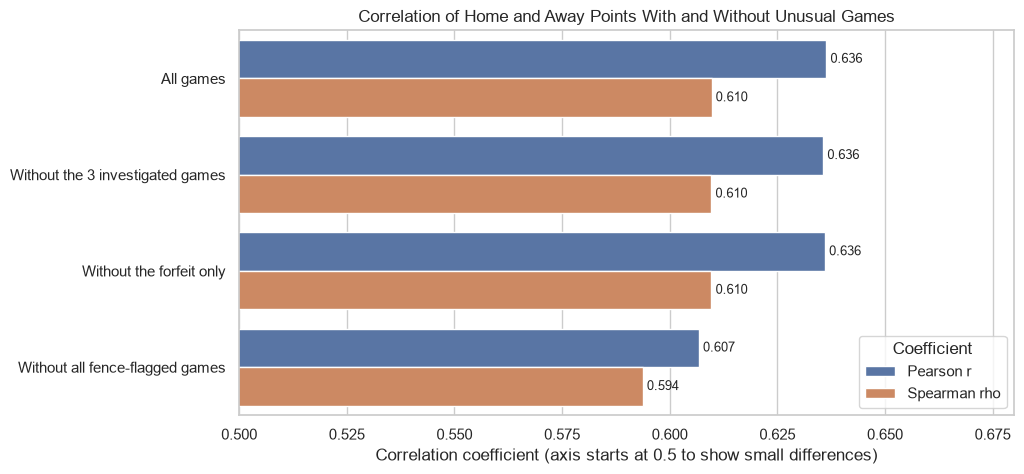

In [12]:
# Unusual-observation visualization 2: how the correlation changes when unusual games are removed
plot_df = outlier_effect[["Pearson r", "Spearman rho"]].reset_index().melt(
    id_vars="index", var_name="Coefficient", value_name="Correlation")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, y="index", x="Correlation", hue="Coefficient",
            palette=["#4C72B0", "#DD8452"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3, fontsize=9)
ax.set_xlim(0.5, 0.68)
ax.set_title("Correlation of Home and Away Points With and Without Unusual Games")
ax.set_xlabel("Correlation coefficient (axis starts at 0.5 to show small differences)")
ax.set_ylabel("")
plt.show()

**Do the unusual observations influence the relationship?**

- **The individual games do not.** Removing the forfeit, the 18–19 game and the 186–184 game changes Pearson r only in the third decimal (≈ 0.636 → 0.636). Three points among 55,451 games cannot move a correlation, even when they are very extreme — they lie roughly on the overall diagonal trend anyway.
- **The group of fence-flagged games does, slightly.** Removing all 943 flagged games lowers Pearson from ≈ 0.636 to ≈ 0.607 and Spearman from ≈ 0.610 to ≈ 0.594. The flagged games lie at the two ends of the diagonal, so they *strengthen* the linear pattern; Pearson reacts more than Spearman because it weighs extreme values more heavily.
- **Decision:** I keep all observations in the analysis. They are genuine games (only the forfeit is not a real performance, and it has no measurable effect). Rather than being errors, the flagged games mainly reflect the *early era*, which points to the more important issue explored in Section 7: differences *between eras* inflate the overall correlation.

## 6. Numerical vs Categorical

**Main comparison:** `pts` (numerical) across `era` (categorical). Here I use all team-game rows (both teams' scores), since the question is about scoring per team-game, not per game.

In [13]:
df["era"] = pd.cut(df["year_id"], bins=ERA_BINS, labels=ERA_LABELS)

era_stats = df.groupby("era", observed=True)["pts"].describe()[["count", "mean", "25%", "50%", "75%", "std", "min", "max"]]
era_stats["IQR"] = era_stats["75%"] - era_stats["25%"]
era_stats.round(1)

,count,mean,25%,50%,75%,std,min,max,IQR
era,,,,,,,,,
1947-54,5988.0,79.3,71.0,79.0,88.0,12.9,18.0,141.0,17.0
1955-69,13328.0,111.3,102.0,111.0,121.0,13.8,57.0,173.0,19.0
1970-79,22426.0,109.1,100.0,109.0,117.0,12.9,0.0,177.0,17.0
1980-94,31982.0,107.6,99.0,107.0,116.0,12.8,59.0,186.0,17.0
1995-2009,37178.0,96.9,88.0,97.0,105.0,12.3,49.0,168.0,17.0


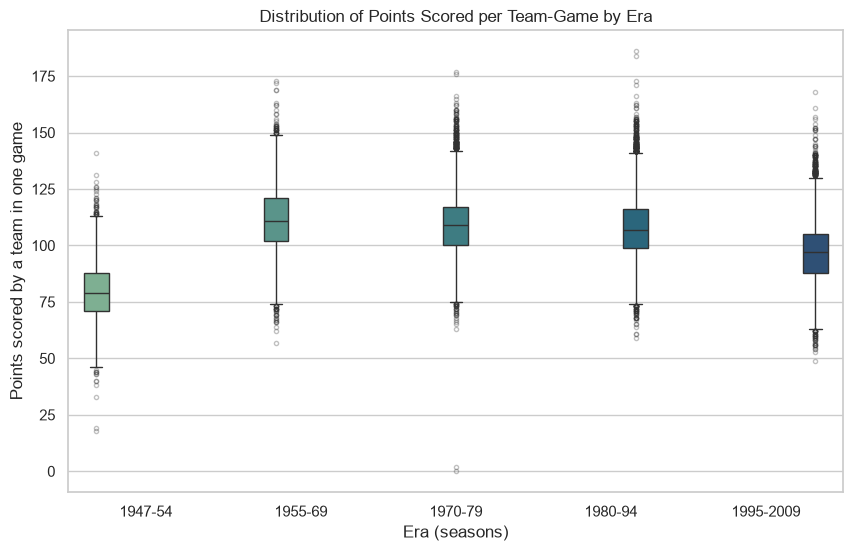

In [14]:
# Group-comparison plot 1: boxplot of points per team-game by era
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="era", y="pts", hue="era", palette="crest", legend=False,
            flierprops=dict(marker=".", alpha=0.3), ax=ax)
ax.set_title("Distribution of Points Scored per Team-Game by Era")
ax.set_xlabel("Era (seasons)")
ax.set_ylabel("Points scored by a team in one game")
plt.show()

**Interpretation:**
- **Medians:** the typical team score jumps from **79** points in 1947–54 to **111** in 1955–69 — the largest change between neighbouring eras, coinciding with the introduction of the shot clock. Medians then decline gradually: 109 (1970s), 107 (1980–94) and **97** in 1995–2009.
- **Spread:** the IQR is very similar across eras (17–19 points) and so is the standard deviation (~12–14), so eras differ mainly in their *level* of scoring, not in how variable scoring is.
- **Overlap and differences:** the four eras from 1955 onwards overlap heavily (e.g. the 1970s and 1980–94 boxes are almost identical), while the 1947–54 era barely overlaps with 1955–69: its upper quartile (88) lies below the 1955–69 lower quartile (102). The 1995–2009 era is visibly lower than the three before it, but still overlaps substantially.
- **Outliers:** each era has outliers on both sides. The most notable are the forfeit (0 and 2 points) in 1970–79, the 18–19 game in 1947–54, and the 186–184 record in 1980–94. Given the era medians, a "high" score is relative: 120 points would be an outlier in 1947–54 but completely ordinary in the 1960s.
- **Main pattern:** era is a strong source of variation in scoring. This is exactly the kind of *hidden group* that can affect correlations that pool all seasons (Section 7).

**Second group comparison:** home-team `margin` by `season_type` (regular season vs playoffs), one row per game.

In [15]:
st_stats = games.groupby("season_type")[["margin", "abs_margin", "elo_diff"]].agg(["median", "mean", "std"]).round(2)
st_stats["home win rate"] = games.groupby("season_type")["home_win"].mean().round(3)
st_stats

margin              abs_margin              elo_diff               home win rate
               median  mean    std     median   mean   std   median  mean     std              
season_type                                                                                    
Playoffs          5.0  4.62  12.15        9.0  10.43  7.76     7.93  8.16   98.09         0.660
Regular season    4.0  3.81  12.82        9.0  10.75  7.96    -1.03 -1.13  151.66         0.624

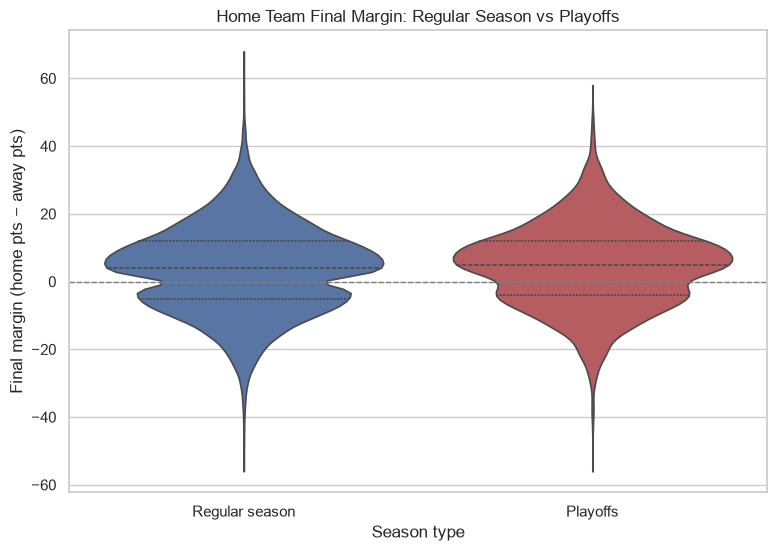

In [16]:
# Group-comparison plot 2: violin plot of home margin by season type
fig, ax = plt.subplots(figsize=(9, 6))
sns.violinplot(data=games, x="season_type", y="margin", hue="season_type",
               palette={"Regular season": "#4C72B0", "Playoffs": "#C44E52"},
               inner="quartile", cut=0, legend=False, ax=ax)
ax.axhline(0, color="gray", lw=1, ls="--")
ax.set_title("Home Team Final Margin: Regular Season vs Playoffs")
ax.set_xlabel("Season type")
ax.set_ylabel("Final margin (home pts − away pts)")
plt.show()

**Interpretation:** both violins have almost the same shape: centred a little above zero, with quartiles spanning roughly −5 to +12. The playoff distribution is shifted slightly upward (median margin +5 vs +4; home win rate ≈ 66% vs ≈ 62%) and is a little narrower. A large part of this playoff shift is explained by another variable: in the playoffs, home court is *given to the better-seeded team*, so the home team has, on average, an Elo advantage of about +8 points, compared with about −1 in the regular season. The extreme tails (losses or wins by 50+) exist in both groups. **Main pattern:** the distributions overlap almost completely; season type changes the typical margin only slightly.

## 7. Relationships Across Groups

**(a) `pts` vs `opp_pts`, split by `era`.**

In [17]:
era_corr = games.groupby("era", observed=True).apply(
    lambda g: pd.Series({"n games": len(g), "Pearson r": pearson(g["pts"], g["opp_pts"]),
                         "Spearman rho": spearman(g["pts"], g["opp_pts"]),
                         "mean pts": g["pts"].mean()}),
    include_groups=False,
)
era_corr.loc["ALL GAMES (pooled)"] = [len(games), pearson(games["pts"], games["opp_pts"]),
                                      spearman(games["pts"], games["opp_pts"]), games["pts"].mean()]

# Remove the between-season differences by subtracting each season's average
dm = games[["pts", "opp_pts"]] - games.groupby("year_id")[["pts", "opp_pts"]].transform("mean")
print(f"Correlation after subtracting each season's mean: r = {pearson(dm['pts'], dm['opp_pts']):.3f}")
era_corr.round(3)

Correlation after subtracting each season's mean: r = 0.447


,n games,Pearson r,Spearman rho,mean pts
era,,,,
1947-54,2994.0,0.527,0.499,81.270
1955-69,6664.0,0.552,0.536,113.001
1970-79,11213.0,0.505,0.486,111.169
1980-94,15991.0,0.489,0.463,109.826
1995-2009,18589.0,0.445,0.417,98.559
ALL GAMES (pooled),55451.0,0.636,0.610,105.160


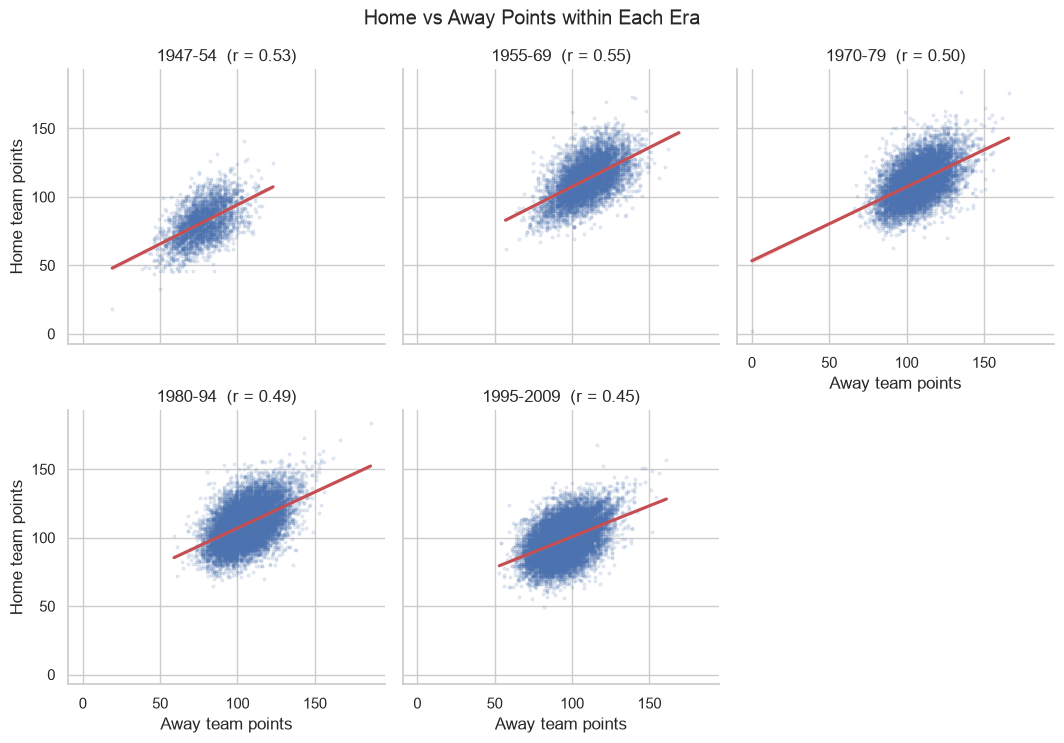

In [18]:
g = sns.lmplot(data=games, x="opp_pts", y="pts", col="era", col_wrap=3, height=3.6,
               scatter_kws=dict(s=4, alpha=0.12, rasterized=True), line_kws=dict(color="#C44E52"),
               facet_kws=dict(sharex=True, sharey=True))
for ax, era in zip(g.axes.flat, ERA_LABELS):
    r = era_corr.loc[era, "Pearson r"]
    ax.set_title(f"{era}  (r = {r:.2f})")
g.set_axis_labels("Away team points", "Home team points")
g.figure.suptitle("Home vs Away Points within Each Era", y=1.03)
plt.show()

**Interpretation (a):** within every era the relationship stays **positive and linear**, but it is **weaker than in the pooled data**: the within-era Pearson values range from about 0.45 to 0.55, while the pooled value is about 0.64. Subtracting each season's average gives r ≈ 0.45. Each era's point cloud is centred at a different location along the diagonal (around 80 points in 1947–54, around 110 in the 1960s), so stacking the eras stretches the cloud along the diagonal and makes the pooled correlation look stronger than the relationship within any single period.

**Hidden pattern revealed:** roughly a third of the overall correlation is a *between-era* effect — when the whole league scores more, both teams score more. The remaining within-era correlation (≈ 0.45–0.55) reflects game-level factors such as pace and overtime. The correlation is also weakest in the most recent era (≈ 0.45).

**(b) `elo_diff` vs `margin`, split by `season_type`.**

In [19]:
st_corr = games.groupby("season_type").apply(
    lambda g: pd.Series({"n games": len(g), "Pearson r": pearson(g["elo_diff"], g["margin"]),
                         "Spearman rho": spearman(g["elo_diff"], g["margin"]),
                         "slope (pts per 100 Elo)": 100 * np.polyfit(g["elo_diff"], g["margin"], 1)[0],
                         "std of elo_diff": g["elo_diff"].std()}),
    include_groups=False,
)
st_corr.round(3)

,n games,Pearson r,Spearman rho,slope (pts per 100 Elo),std of elo_diff
season_type,,,,,
Playoffs,3466.0,0.296,0.291,3.670,98.091
Regular season,51985.0,0.415,0.412,3.507,151.661


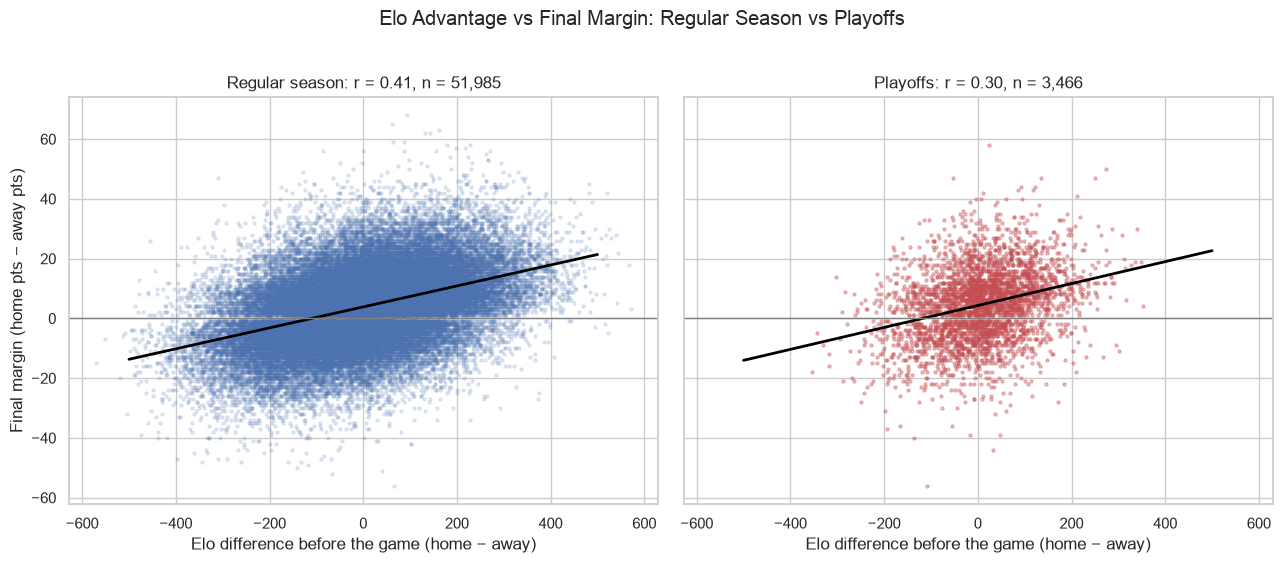

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, (st, color) in zip(axes, [("Regular season", "#4C72B0"), ("Playoffs", "#C44E52")]):
    sub = games[games["season_type"] == st]
    ax.scatter(sub["elo_diff"], sub["margin"], s=5, alpha=0.15 if st == "Regular season" else 0.35,
               color=color, rasterized=True)
    b1_, b0_ = np.polyfit(sub["elo_diff"], sub["margin"], 1)
    xs = np.array([-500, 500])
    ax.plot(xs, b0_ + b1_ * xs, color="black", lw=2)
    ax.axhline(0, color="gray", lw=1)
    ax.set_title(f"{st}: r = {st_corr.loc[st, 'Pearson r']:.2f}, n = {len(sub):,}")
    ax.set_xlabel("Elo difference before the game (home − away)")
axes[0].set_ylabel("Final margin (home pts − away pts)")
fig.suptitle("Elo Advantage vs Final Margin: Regular Season vs Playoffs", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation (b):** the direction is the same in both groups (positive) and the slopes are similar, but the relationship is clearly **weaker in the playoffs** (r ≈ 0.30 vs ≈ 0.42). The plot shows why: playoff points are squeezed horizontally — playoff opponents are both good teams, so the spread of `elo_diff` is much smaller (std ≈ 98 vs ≈ 152). With a narrower range of Elo gaps but the same game-to-game noise in the margin, the correlation must drop. This is a **restriction-of-range** effect: it does *not* mean Elo is less meaningful in the playoffs; it means there is less difference in team strength for Elo to explain. The pooled correlation hides this.

## 8. Correlation Matrix

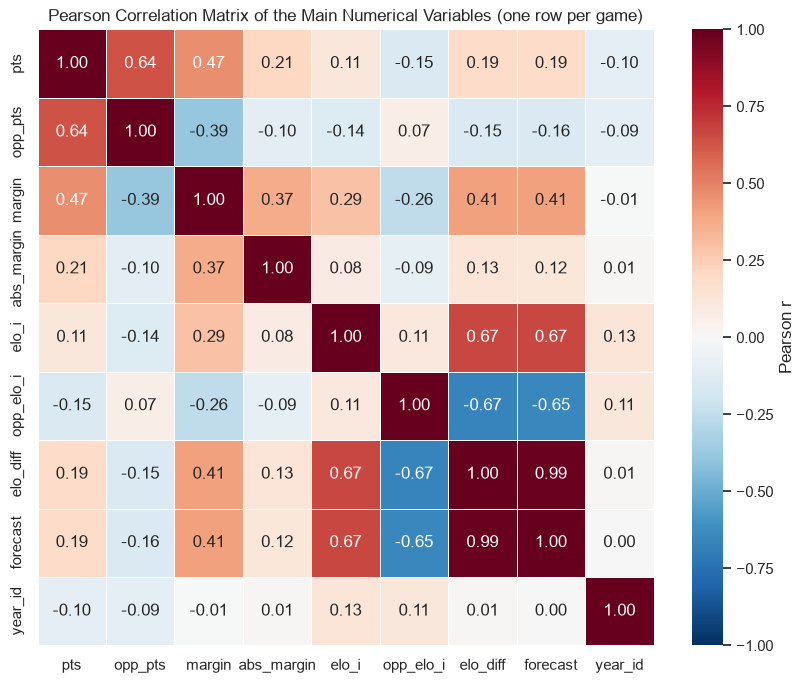

Most negative pairs:
 opp_elo_i  elo_diff   -0.666
           forecast   -0.651
opp_pts    margin     -0.386

Most positive pairs:
 pts       opp_pts     0.636
elo_i     elo_diff    0.670
          forecast    0.671
elo_diff  forecast    0.989

Weakest pairs (closest to 0):
 forecast  year_id    0.004
margin    year_id    0.007
elo_diff  year_id    0.012


In [21]:
main_vars = ["pts", "opp_pts", "margin", "abs_margin", "elo_i", "opp_elo_i", "elo_diff", "forecast", "year_id"]
corr_matrix = games[main_vars].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws=dict(label="Pearson r"), ax=ax)
ax.set_title("Pearson Correlation Matrix of the Main Numerical Variables (one row per game)")
plt.show()

pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack().dropna().sort_values()
print("Most negative pairs:\n", pairs.head(3).round(3).to_string())
print("\nMost positive pairs:\n", pairs.tail(4).round(3).to_string())
print("\nWeakest pairs (closest to 0):\n", pairs.abs().sort_values().head(3).round(3).to_string())

**Interpretation:**

- **Strongest positive:** `elo_diff` vs `forecast` (r ≈ 0.99). This is close to perfect **by construction** — FiveThirtyEight's win probability is a smooth function of the Elo difference (plus a home-court adjustment), so it reflects how the variables were defined, not a discovery. The strongest positive relationship between variables that are *not* derived from one another is **`pts` vs `opp_pts` (r ≈ 0.64)**.
- **Strongest negative:** `elo_diff` vs `opp_elo_i` (r ≈ −0.67), again largely mechanical (`opp_elo_i` is subtracted to form `elo_diff`). The strongest negative association between outcome variables is **`opp_pts` vs `margin` (r ≈ −0.39)**: the more the away team scores, the smaller the home margin.
- **Weak relationship:** `year_id` vs `elo_diff` (r ≈ 0.01) — reasonable, since Elo is relative (zero-sum), so the average rating gap does not drift over time. `year_id` vs `margin` and vs `forecast` are also ≈ 0.
- **Agreement with the scatterplots:**
  - `elo_diff` vs `margin` (0.41) and `pts` vs `opp_pts` (0.64) match the scatterplots in Section 2: a wide upward band and a tighter diagonal ellipse.
  - `year_id` vs `pts` (−0.10) is where the heatmap **disagrees** with the plot: it suggests almost no relationship, but the Section 4 plot shows a strong rise-and-fall pattern. A correlation matrix only measures *linear* association and can hide strong non-linear patterns, which is why each pair should also be plotted.

## 9. Correlation ≠ Causation

**Relationship chosen:** `pts` vs `opp_pts` (r ≈ 0.64).

A naive reading would be: *"when a team scores more, it causes its opponent to score more"* (e.g. fast scoring leads to fast counter-attacks). The data cannot support that conclusion:

- **Confounding variables:** both scores share the same *game environment*.
  - **Era and rules** — the shot clock (1954), the three-point line (1979) and changes in defensive rules move both teams' scoring up or down together. Section 7 showed that the correlation falls from 0.64 to about 0.45 once differences between seasons are removed, so a large part of the association comes from this confounder.
  - **Pace** (number of possessions) — a fast game gives both teams more chances to score. Possessions are not recorded in this dataset, so this confounder cannot be measured here.
  - **Overtime** — extra periods add minutes for both teams (e.g. the 186–184 triple-overtime game).
- **Reverse causality:** even if one score did influence the other, the direction would be unclear — a team trailing might speed up and score more *because* its opponent scored a lot, rather than the other way around.
- **Hidden groups:** pooling five eras with very different scoring levels inflated the correlation (Section 7) — a classic hidden-group effect.
- **Selection effects:** the data contains only NBA/ABA games that were played and recorded; the forfeit shows that some "results" are not real gameplay at all.

**Conclusion:** the positive correlation is real and useful for description ("high-scoring games are high-scoring for both sides"), but it is best explained by shared conditions affecting both teams, not by one team's points causing the other's. Testing a causal claim would require controlling for pace, overtime and era — or an experiment, which is impossible here.

## 10. New EDA Questions

1. **Does the within-game correlation between home and away points disappear once pace and overtime are accounted for?** The dataset has no possession counts or overtime flag; joining box-score data (or using the 186–184 type games as a hint, flagging likely overtime games by unusually high total scores) would show how much of the remaining ≈ 0.45 is explained by game length and tempo.
2. **Is the Elo forecast as well calibrated in the playoffs as in the regular season?** The `elo_diff`–`margin` correlation was weaker in the playoffs (restricted range), but that does not tell us whether forecast probabilities match actual playoff win rates.
3. **Does the relationship between Elo gap and margin weaken late in the regular season** (high `seasongame`), when teams that are out of contention may rest players or "tank"?
4. **Why is the `pts`–`opp_pts` correlation weakest in 1995–2009?** Did the slower, more defensive style of that era make game scores less dependent on shared pace?

## Additional Bivariate Visualizations

Two more views of Pair 1, which deal with the problem of 55,000 overlapping points and connect to the A1 question about whether the Elo forecast predicts outcomes.

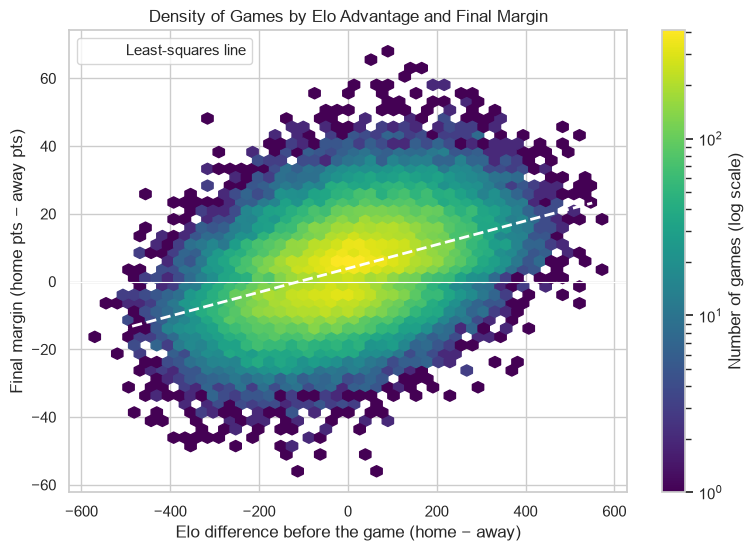

In [22]:
# Additional visualization 1: hexbin density of elo_diff vs margin
fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(games["elo_diff"], games["margin"], gridsize=45, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Number of games (log scale)")
xs = np.array([-550, 550])
ax.plot(xs, intercept + slope * xs, color="white", lw=2, ls="--", label="Least-squares line")
ax.axhline(0, color="white", lw=0.8)
ax.set_title("Density of Games by Elo Advantage and Final Margin")
ax.set_xlabel("Elo difference before the game (home − away)")
ax.set_ylabel("Final margin (home pts − away pts)")
ax.legend(loc="upper left")
plt.show()

**Interpretation:** the scatterplot in Section 2 makes the extreme games look important because every point is drawn at the same size. The hexbin shows where the games actually are: the large majority lie in a compact core of Elo gaps within about ±200 and margins within about ±20, centred slightly above zero. The density increases along the fitted line — the positive relationship is visible in the *bulk* of the data, not only in the tails — but even at the densest point a wide range of margins is common.

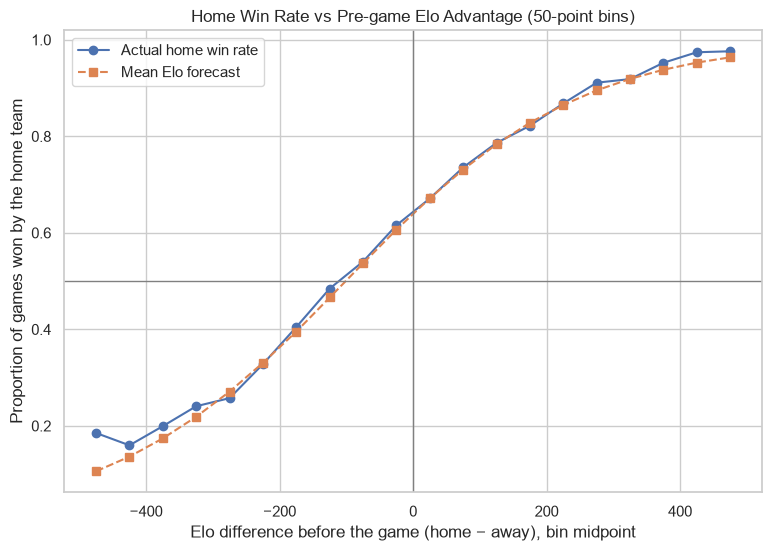

In [23]:
# Additional visualization 2: binned Elo advantage vs actual home win rate and Elo forecast
games["elo_bin"] = pd.cut(games["elo_diff"], bins=np.arange(-500, 501, 50))
calib = games.groupby("elo_bin", observed=True).agg(
    n=("home_win", "size"), win_rate=("home_win", "mean"), forecast=("forecast", "mean"))
calib["mid"] = [iv.mid for iv in calib.index]
calib = calib[calib["n"] >= 30]

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(calib["mid"], calib["win_rate"], "o-", color="#4C72B0", label="Actual home win rate")
ax.plot(calib["mid"], calib["forecast"], "s--", color="#DD8452", label="Mean Elo forecast")
ax.axhline(0.5, color="gray", lw=1)
ax.axvline(0, color="gray", lw=1)
ax.set_title("Home Win Rate vs Pre-game Elo Advantage (50-point bins)")
ax.set_xlabel("Elo difference before the game (home − away), bin midpoint")
ax.set_ylabel("Proportion of games won by the home team")
ax.legend()
plt.show()

**Interpretation:** the *probability* of winning has a clearly **S-shaped (non-linear)** relationship with the Elo gap: it rises steeply around a gap of 0 and flattens towards 0 and 1 at the extremes, since a win probability cannot exceed 100%. The actual win rate (blue) follows the Elo forecast (orange) very closely in almost every bin, so the forecast is well calibrated. The only visible gap is at the most extreme negative Elo gaps (few games), where heavy home underdogs win somewhat more often than forecast. Together with Pair 1, this shows that Elo predicts *who wins* well, while *by how much* remains much noisier (r ≈ 0.41 with the margin). At an Elo gap of 0 the home team still wins about 62–67% of games — the home-court advantage again.

## Final Interpretation

**Strongest relationship.** Leaving aside pairs that are related by construction (e.g. `elo_diff` and `forecast`, r ≈ 0.99), the strongest relationship was between home and away points (Pearson ≈ 0.64, Spearman ≈ 0.61). The pre-game Elo gap and the final margin were only moderately related (≈ 0.41).

**Most interesting.** The `pts`–`opp_pts` relationship was the most interesting, because it is *not* about one team beating another. Both scores rise and fall together because both teams share the same era, rules, pace and overtime. Splitting by era showed that about a third of the correlation comes from differences between eras.

**Pearson vs Spearman.** They agreed almost exactly for Elo gap vs margin (0.41 vs 0.41), showing a linear relationship that does not depend on outliers. For home vs away points Pearson was slightly higher, because extreme games that lie along the diagonal (very low-scoring early games, very high-scoring overtime games) add weight to the linear trend. For season vs points they disagreed (−0.10 vs −0.21), and neither described the pattern.

**Nonlinearity.** Yes. Scoring by season follows a rise–plateau–decline pattern (69 → ~120 → ~95 points), which a straight line and Pearson's r ≈ −0.10 completely miss. The win probability also has an S-shaped relationship with the Elo gap.

**Unusual observations.** The individual A2 outliers (the forfeit, the 186–184 and 19–18 games) had no measurable effect on r, since three games out of 55,451 cannot move it. Removing all 943 fence-flagged games lowered r from 0.636 to 0.607, because those games are concentrated at both ends of the diagonal, and especially in the 1947–54 era.

**Grouping.** Yes. Within each era the `pts`–`opp_pts` correlation was only 0.45–0.55, lower than the pooled 0.64. The Elo–margin correlation dropped from 0.42 in the regular season to 0.30 in the playoffs. This is a restriction-of-range effect: playoff opponents are closer in strength, so there is less difference for Elo to explain.

**Next.** I would study how much of the remaining within-era scoring correlation is explained by pace and overtime, and whether the Elo forecast is equally well calibrated in the playoffs.

**Association ≠ causation.** A correlation only shows that two variables move together. Here confounders (era, rules, pace, overtime), possible reverse causality and hidden groups all produce associations without one variable *causing* the other. The Elo–margin link is not causal either: Elo is a summary of past results, not something that makes a team win, and the underlying cause (team quality, roster, health) drives both.